# LLM Hallucination Detection using HaluEval
## Model Evaluation, Results and Analysis

### Objective
This notebook evaluates the two trained classifiers (TF-IDF with Logistic Regression and TF-IDF with LinearSVC) on the held-out test set. It compares them with simple baselines, tests whether the results are affected by answer length, analyses the errors, and selects the best model.

### Evaluation setup
- **Test data:** `halu_test.csv` contains 4,000 instances (2,000 questions with two candidate answers each). It was separated from the training data before restructuring and was not used for training or hyperparameter tuning.
- **Positive class:** Hallucinated (1), since the goal of the project is to detect hallucinated answers.
- **Metrics:** Accuracy, Precision, Recall and F1-score, as stated in the project proposal. ROC-AUC is added as a threshold-independent measure.
- **No re-training of the models:** The saved pipelines are used as they are. Two simple baselines are trained on the training set only, and the test set is used once for the final evaluation.

### Contents
1. Environment setup and data loading
2. Predictions
3. Performance metrics
4. Baselines
5. Confusion matrices
6. Comparison charts
7. Statistical comparison
8. Length-controlled evaluation
9. Error analysis
10. Best-model selection
11. Saving the results
12. Conclusion

## 1. Environment Setup and Data Loading

The saved pipelines were trained with scikit-learn 1.6.1. To avoid version incompatibilities when unpickling them, the same version is installed first. If Colab asks to restart the runtime after the installation, restart it and continue from the next cell.

In [1]:
!pip install -q scikit-learn==1.6.1

In [2]:
import os
import shutil

import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt

from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
CLASS_NAMES = ["Faithful (0)", "Hallucinated (1)"]

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


Four files are required: the test set, the training set (needed for the baselines and for the training-set scores), and the two saved pipelines. They are uploaded manually, and two folders are created for the tables and figures produced later.

In [4]:
from google.colab import files

uploaded = files.upload()

TRAIN_CSV = "halu_train.csv"
TEST_CSV = "halu_test.csv"
LR_MODEL_FILE = "best_logistic_regression_model.pkl"
SVM_MODEL_FILE = "best_svm_pipeline.pkl"

RESULTS_DIR = "results"
TABLES_DIR = os.path.join(RESULTS_DIR, "tables")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

Saving best_logistic_regression_model.pkl to best_logistic_regression_model.pkl
Saving best_svm_pipeline.pkl to best_svm_pipeline.pkl
Saving halu_test.csv to halu_test.csv
Saving halu_train.csv to halu_train.csv


### 1.1 Datasets
Both files are inspected for missing values and class balance. Since every question should have exactly one faithful and one hallucinated answer, this structure is also verified because it is used in the later analysis. The overlap of questions between the two files is checked to confirm that there is no leakage.

In [5]:
train_data = pd.read_csv(TRAIN_CSV)
test_data = pd.read_csv(TEST_CSV)

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)
print("Columns:", test_data.columns.tolist())
print("\nMissing values (test):\n", test_data.isna().sum())

print("\nLabel counts (test):")
print(test_data["label"].value_counts().sort_index())

for name, data in [("train", train_data), ("test", test_data)]:
    assert set(data["label"].unique()) == {0, 1}
    assert data["question"].value_counts().eq(2).all()
    assert data.groupby("question")["label"].agg(set).apply(lambda s: s == {0, 1}).all()

shared_questions = set(train_data["question"]) & set(test_data["question"])
print("\nUnique questions (test):", test_data["question"].nunique())
print("Questions shared between train and test:", len(shared_questions))
print("Structure checks passed.")

Train shape: (16000, 5)
Test shape: (4000, 5)
Columns: ['knowledge', 'question', 'answer', 'label', 'text']

Missing values (test):
 knowledge    0
question     0
answer       0
label        0
text         0
dtype: int64

Label counts (test):
label
0    2000
1    2000
Name: count, dtype: int64

Unique questions (test): 2000
Questions shared between train and test: 0
Structure checks passed.


### 1.2 Saved models
Each file contains a complete pipeline (TF-IDF vectorizer followed by the classifier), so raw text can be passed to it directly. The models are stored in a dictionary, so an additional model can be evaluated by adding one entry to it, one entry to `KEY`, and one to `COLORS`. The two models compared in the pairwise tests are named `MODEL_A` and `MODEL_B`.

In [6]:
models = {
    "Logistic Regression": joblib.load(LR_MODEL_FILE),
    "SVM (LinearSVC)": joblib.load(SVM_MODEL_FILE),
}

KEY = {"Logistic Regression": "lr", "SVM (LinearSVC)": "svm"}
COLORS = {
    "Logistic Regression": "#4C72B0",
    "SVM (LinearSVC)": "#DD8452",
    "Majority class": "#9A9A9A",
    "Answer length only": "#55A868",
}

MODEL_A = "Logistic Regression"
MODEL_B = "SVM (LinearSVC)"

for name, model in models.items():
    print(f"{name}:")
    for step_name, step in model.steps:
        print(f"   {step_name}: {step}")

Logistic Regression:
   tfidf: TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
   logreg: LogisticRegression(C=10, max_iter=1000, random_state=42)
SVM (LinearSVC):
   tfidf: TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
   svm: LinearSVC(max_iter=5000, random_state=42)


## 2. Predictions

Both pipelines predict the class labels of the test set. A continuous score is also extracted for the ROC analysis: the predicted probability of the Hallucinated class for Logistic Regression, and the signed distance to the decision boundary for LinearSVC, which does not output probabilities.

In [7]:
X_train = train_data["text"]
y_train = train_data["label"].to_numpy()
X_test = test_data["text"]
y_test = test_data["label"].to_numpy()

preds, scores = {}, {}

for name, model in models.items():
    preds[name] = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        scores[name] = model.predict_proba(X_test)[:, 1]
    else:
        scores[name] = model.decision_function(X_test)

    print(f"{name}: predicted hallucinated = {(preds[name] == 1).sum()}, "
          f"predicted faithful = {(preds[name] == 0).sum()}")

Logistic Regression: predicted hallucinated = 1775, predicted faithful = 2225
SVM (LinearSVC): predicted hallucinated = 1769, predicted faithful = 2231


## 3. Performance Metrics

Accuracy, Precision, Recall and F1-score are computed for each model, with Hallucinated (1) as the positive class. Precision is the share of flagged answers that are truly hallucinated, and Recall is the share of hallucinated answers that are detected.

In [8]:
def evaluate(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

results = pd.DataFrame(
    {name: evaluate(y_test, preds[name], scores[name]) for name in models}
).T
results.index.name = "Model"

print("Table 1. Test-set performance (positive class = Hallucinated)")
display(results.round(4))

Table 1. Test-set performance (positive class = Hallucinated)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7292,0.7583,0.6730,0.7131,0.8067
SVM (LinearSVC),0.7312,0.7614,0.6735,0.7148,0.8076


The per-class reports show whether each model treats the two classes differently.

In [9]:
for name, p in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, p, target_names=CLASS_NAMES, digits=4))

Logistic Regression
                  precision    recall  f1-score   support

    Faithful (0)     0.7061    0.7855    0.7437      2000
Hallucinated (1)     0.7583    0.6730    0.7131      2000

        accuracy                         0.7292      4000
       macro avg     0.7322    0.7292    0.7284      4000
    weighted avg     0.7322    0.7292    0.7284      4000

SVM (LinearSVC)
                  precision    recall  f1-score   support

    Faithful (0)     0.7073    0.7890    0.7459      2000
Hallucinated (1)     0.7614    0.6735    0.7148      2000

        accuracy                         0.7312      4000
       macro avg     0.7344    0.7312    0.7304      4000
    weighted avg     0.7344    0.7312    0.7304      4000



The test F1-score is compared with the F1-score on the training set and with the mean cross-validation F1-score obtained by Students 1 and 2. A small difference between the cross-validation and test scores indicates that the validation estimate was reliable. A large difference between the training and test scores indicates overfitting.

In [10]:
validation_f1 = {"Logistic Regression": 0.7182, "SVM (LinearSVC)": 0.7194}

generalisation = pd.DataFrame({
    name: {
        "Validation F1 (CV)": validation_f1.get(name, np.nan),
        "Train F1": f1_score(y_train, models[name].predict(X_train), pos_label=1),
        "Test F1": results.loc[name, "F1-score"],
        "Train accuracy": accuracy_score(y_train, models[name].predict(X_train)),
        "Test accuracy": results.loc[name, "Accuracy"],
    }
    for name in models
}).T
generalisation["Train - Test F1"] = generalisation["Train F1"] - generalisation["Test F1"]
generalisation["Test - CV F1"] = generalisation["Test F1"] - generalisation["Validation F1 (CV)"]
generalisation.index.name = "Model"

print("Table 2. Cross-validation, training and test performance")
display(generalisation.round(4))

Table 2. Cross-validation, training and test performance


,Validation F1 (CV),Train F1,Test F1,Train accuracy,Test accuracy,Train - Test F1,Test - CV F1
Model,,,,,,,
Logistic Regression,0.7182,0.8698,0.7131,0.8741,0.7292,0.1567,-0.0051
SVM (LinearSVC),0.7194,0.8729,0.7148,0.8779,0.7312,0.1581,-0.0046


In [11]:
ranked = results.sort_values(["F1-score", "Recall"], ascending=False)
best_model_name = ranked.index[0]
other_model_name = ranked.index[1]

print("Highest test F1:", best_model_name)

Highest test F1: SVM (LinearSVC)


## 4. Baselines

An F1-score of about 0.71 is only informative when it is compared with simple reference systems. In the HaluEval QA data, the original answers are usually short entities, whereas the hallucinated answers are generated sentences, so answer length may act as a shortcut that does not require any understanding of the knowledge. Two baselines are therefore added:

1. **Majority class:** always predicts the most frequent class of the training set.
2. **Answer length only:** a Logistic Regression trained on three features computed from the answer alone (number of words, logarithm of the number of words, and number of characters). It never sees the knowledge or the question.

Both baselines are trained on the training set only and evaluated once on the test set, in the same way as the two models.

In [12]:
def length_features(df):
    words = df["answer"].str.split().str.len()
    return pd.DataFrame({
        "words": words,
        "log_words": np.log1p(words),
        "chars": df["answer"].str.len(),
    })

baselines = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Answer length only": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}

train_length = length_features(train_data)
test_length = length_features(test_data)

baseline_preds, baseline_scores = {}, {}

for name, baseline in baselines.items():
    baseline.fit(train_length, y_train)
    baseline_preds[name] = baseline.predict(test_length)
    baseline_scores[name] = baseline.predict_proba(test_length)[:, 1]

all_preds = {**preds, **baseline_preds}
all_scores = {**scores, **baseline_scores}

all_results = pd.DataFrame(
    {name: evaluate(y_test, all_preds[name], all_scores[name]) for name in all_preds}
).T
all_results.index.name = "System"

print("Table 3. Models compared with the baselines on the test set")
display(all_results.round(4))

Table 3. Models compared with the baselines on the test set


,Accuracy,Precision,Recall,F1-score,ROC-AUC
System,,,,,
Logistic Regression,0.7292,0.7583,0.6730,0.7131,0.8067
SVM (LinearSVC),0.7312,0.7614,0.6735,0.7148,0.8076
Majority class,0.5000,0.0000,0.0000,0.0000,0.5000
Answer length only,0.9438,0.9458,0.9415,0.9436,0.9716


## 5. Confusion Matrices

Each matrix shows the true class in the rows and the predicted class in the columns. A false positive (FP) is a faithful answer wrongly flagged as hallucinated, and a false negative (FN) is a hallucinated answer that was missed. The counts are shown first, followed by row-normalised percentages.

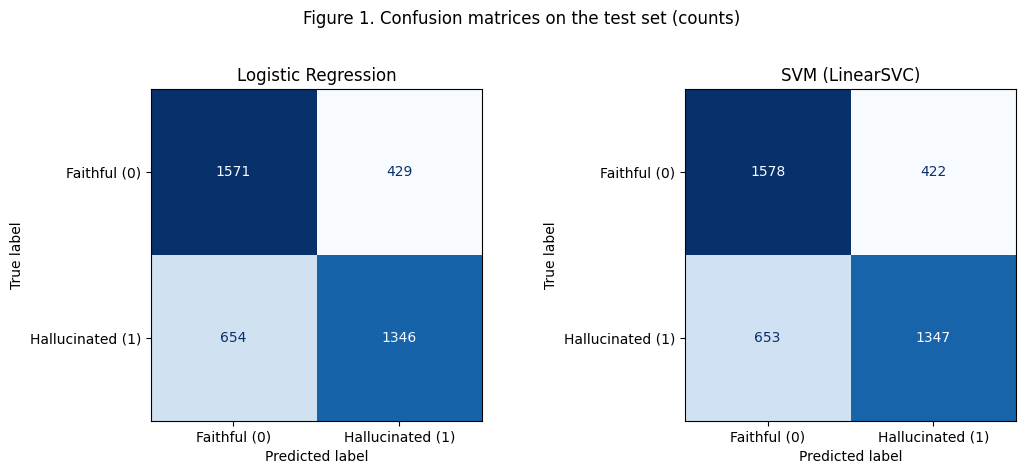

In [13]:
fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.6))

for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 1. Confusion matrices on the test set (counts)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_counts.png"), dpi=200, bbox_inches="tight")
plt.show()

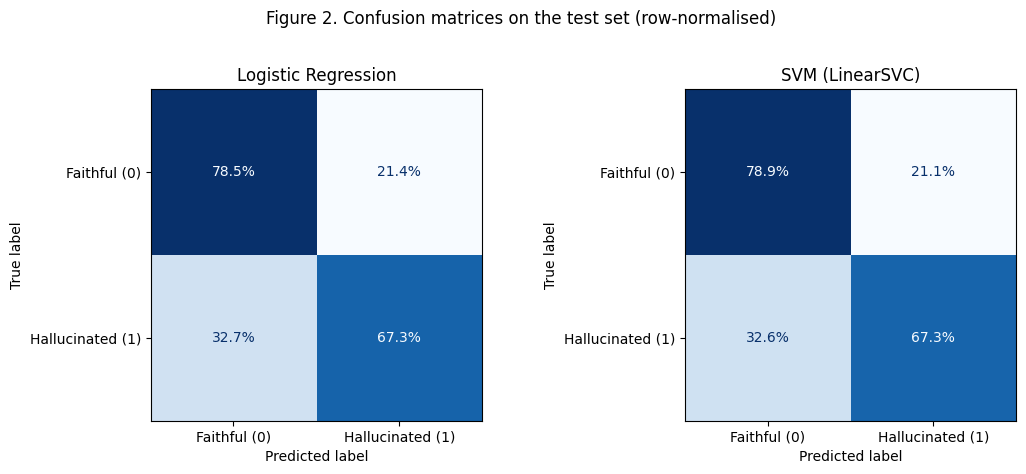

In [14]:
fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.6))

for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    cm_norm = confusion_matrix(y_test, p, labels=[0, 1], normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".1%"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 2. Confusion matrices on the test set (row-normalised)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_normalized.png"), dpi=200, bbox_inches="tight")
plt.show()

In [15]:
cm_rows = []
for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    cm_rows.append({
        "Model": name,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "False positive rate": fp / (fp + tn),
        "False negative rate": fn / (fn + tp),
        "Total errors": fp + fn,
    })

cm_table = pd.DataFrame(cm_rows).set_index("Model")

print("Table 4. Confusion matrix values and error rates")
display(cm_table.round(4))

Table 4. Confusion matrix values and error rates


,TN,FP,FN,TP,False positive rate,False negative rate,Total errors
Model,,,,,,,
Logistic Regression,1571,429,654,1346,0.2145,0.3270,1083
SVM (LinearSVC),1578,422,653,1347,0.2110,0.3265,1075


## 6. Comparison Charts

The metrics of the two models are compared in a bar chart, with the 0.5 chance level of the balanced test set as a reference. The ROC curves show the trade-off between the true positive rate and the false positive rate across all decision thresholds. The last chart places the F1-score of the models next to the baselines.

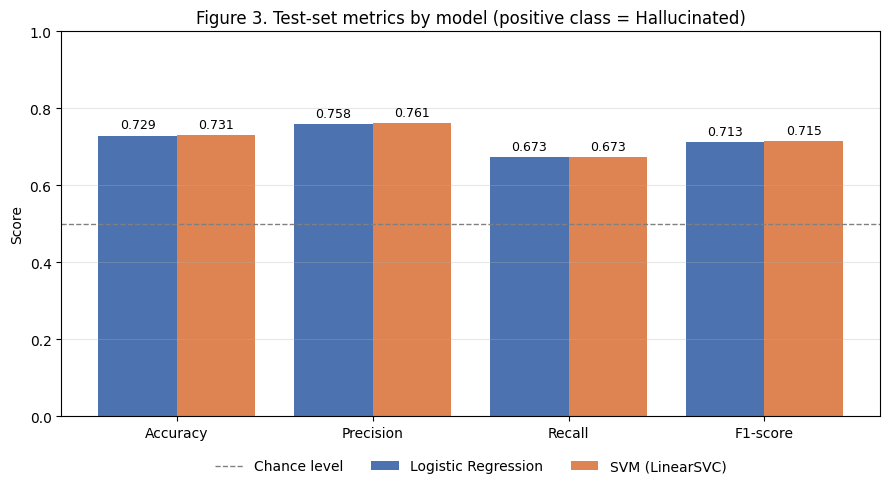

In [16]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metric_names))
width = 0.8 / len(models)

fig, ax = plt.subplots(figsize=(9, 5))

for i, name in enumerate(results.index):
    values = results.loc[name, metric_names].to_numpy()
    offset = (i - (len(models) - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=name, color=COLORS[name])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, fontsize=9)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Chance level")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Figure 3. Test-set metrics by model (positive class = Hallucinated)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "metrics_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

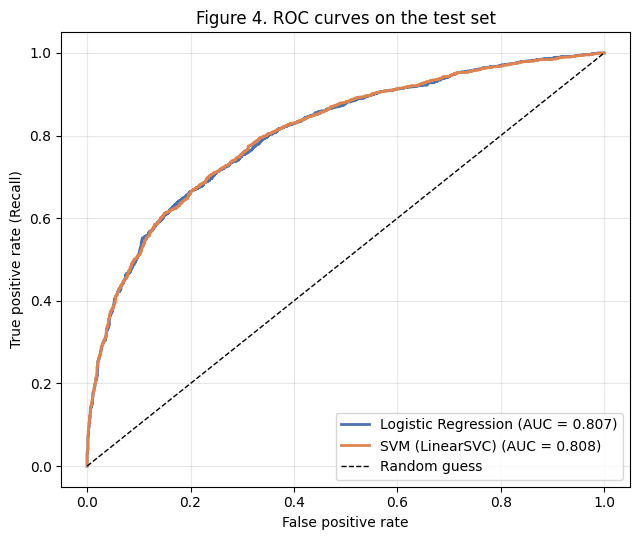

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})",
            color=COLORS[name], linewidth=2)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (Recall)")
ax.set_title("Figure 4. ROC curves on the test set")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

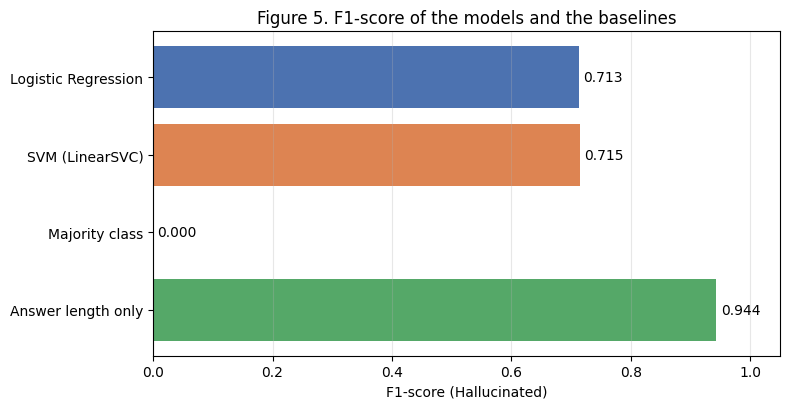

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.2))

names = list(all_results.index)
f1_values = all_results["F1-score"].to_numpy()
bars = ax.barh(names, f1_values, color=[COLORS[n] for n in names])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in f1_values], padding=3)

ax.set_xlim(0, 1.05)
ax.set_xlabel("F1-score (Hallucinated)")
ax.set_title("Figure 5. F1-score of the models and the baselines")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "models_vs_baselines.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Statistical Comparison

The scores of different systems may differ only because of the finite size of the test set. Two complementary methods are used to check this:

1. **McNemar's exact test** compares `MODEL_A` and `MODEL_B` on the same instances and uses only the cases where exactly one of them is correct. The null hypothesis is that both models have the same error rate.
2. **Question-level bootstrap** resamples the 2,000 test questions with replacement (keeping both answers of a question together) 2,000 times. This gives 95% confidence intervals for each metric and for the difference between systems.

First, the predictions are collected in one table that is also used in the error analysis, and McNemar's test is applied.

In [19]:
analysis = test_data.copy()
analysis["answer_words"] = analysis["answer"].str.split().str.len()
analysis["knowledge_words"] = analysis["knowledge"].str.split().str.len()

for name in models:
    k = KEY[name]
    analysis[f"pred_{k}"] = preds[name]
    analysis[f"score_{k}"] = scores[name]
    analysis[f"correct_{k}"] = (preds[name] == y_test)

ka, kb = KEY[MODEL_A], KEY[MODEL_B]
only_a_correct = int((analysis[f"correct_{ka}"] & ~analysis[f"correct_{kb}"]).sum())
only_b_correct = int((~analysis[f"correct_{ka}"] & analysis[f"correct_{kb}"]).sum())
n_discordant = only_a_correct + only_b_correct

mcnemar_p = binomtest(min(only_a_correct, only_b_correct), n_discordant, 0.5).pvalue

print(f"Instances where only {MODEL_A} is correct:", only_a_correct)
print(f"Instances where only {MODEL_B} is correct:", only_b_correct)
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")
print("Significant at 0.05" if mcnemar_p < 0.05 else "Not significant at 0.05")

Instances where only Logistic Regression is correct: 36
Instances where only SVM (LinearSVC) is correct: 44
McNemar exact test p-value: 0.4340
Not significant at 0.05


The bootstrap is then performed. The number of true positives, false positives, false negatives and correct predictions is first counted per question, so that each resample only requires summing these counts. All systems, including the baselines, are evaluated on the same resamples, which allows paired comparisons.

In [20]:
count_names = ["tp", "fp", "fn", "ok", "n"]
N_BOOT = 2000

def per_question_counts(y_true, y_pred, questions):
    tmp = pd.DataFrame({
        "question": questions.to_numpy(),
        "tp": ((y_true == 1) & (y_pred == 1)).astype(int),
        "fp": ((y_true == 0) & (y_pred == 1)).astype(int),
        "fn": ((y_true == 1) & (y_pred == 0)).astype(int),
        "ok": (y_true == y_pred).astype(int),
        "n": 1,
    })
    return tmp.groupby("question").sum()

def metrics_from_counts(c):
    tp, fp, fn, ok, n = c["tp"], c["fp"], c["fn"], c["ok"], c["n"]
    return {
        "Accuracy": ok / n,
        "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "F1-score": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
    }

def bootstrap(count_frames, n_boot=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    arrays = {name: df[count_names].to_numpy() for name, df in count_frames.items()}
    n_q = len(next(iter(arrays.values())))
    out = {name: [] for name in arrays}
    for _ in range(n_boot):
        idx = rng.integers(0, n_q, n_q)
        for name, arr in arrays.items():
            sums = arr[idx].sum(axis=0)
            out[name].append(metrics_from_counts(dict(zip(count_names, sums))))
    return {name: pd.DataFrame(v) for name, v in out.items()}

per_q = {
    name: per_question_counts(y_test, all_preds[name], test_data["question"])
    for name in all_preds
}

boot = bootstrap(per_q)

In [21]:
metric_list = ["Accuracy", "Precision", "Recall", "F1-score"]

ci_rows = []
for name in all_preds:
    point = metrics_from_counts(per_q[name].sum())
    for m in metric_list:
        lo, hi = np.percentile(boot[name][m], [2.5, 97.5])
        ci_rows.append({"System": name, "Metric": m, "Test value": point[m],
                        "95% CI low": lo, "95% CI high": hi})
ci_table = pd.DataFrame(ci_rows)

print("Table 5. Test metrics with 95% bootstrap confidence intervals")
display(ci_table.round(4))

comparisons = [(MODEL_B, MODEL_A), (MODEL_A, "Answer length only"), (MODEL_B, "Answer length only")]

diff_rows = []
for first, second in comparisons:
    p1 = metrics_from_counts(per_q[first].sum())
    p2 = metrics_from_counts(per_q[second].sum())
    for m in metric_list:
        d = boot[first][m] - boot[second][m]
        lo, hi = np.percentile(d, [2.5, 97.5])
        diff_rows.append({
            "Comparison": f"{first} - {second}",
            "Metric": m,
            "Difference (test)": p1[m] - p2[m],
            "95% CI low": lo, "95% CI high": hi,
            "CI contains 0": bool(lo <= 0 <= hi),
        })
diff_table = pd.DataFrame(diff_rows)

print("\nTable 6. Differences between systems")
display(diff_table.round(4))

Table 5. Test metrics with 95% bootstrap confidence intervals


,System,Metric,Test value,95% CI low,95% CI high
0,Logistic Regression,Accuracy,0.7292,0.7180,0.7410
1,Logistic Regression,Precision,0.7583,0.7437,0.7733
2,Logistic Regression,Recall,0.6730,0.6525,0.6940
3,Logistic Regression,F1-score,0.7131,0.6996,0.7267
4,SVM (LinearSVC),Accuracy,0.7312,0.7198,0.7428
5,SVM (LinearSVC),Precision,0.7614,0.7467,0.7768
6,SVM (LinearSVC),Recall,0.6735,0.6525,0.6940
7,SVM (LinearSVC),F1-score,0.7148,0.7011,0.7285
8,Majority class,Accuracy,0.5000,0.5000,0.5000
9,Majority class,Precision,0.0000,0.0000,0.0000



Table 6. Differences between systems


,Comparison,Metric,Difference (test),95% CI low,95% CI high,CI contains 0
0,SVM (LinearSVC) - Logistic Regression,Accuracy,0.0020,-0.0022,0.0063,True
1,SVM (LinearSVC) - Logistic Regression,Precision,0.0031,-0.0024,0.0086,True
2,SVM (LinearSVC) - Logistic Regression,Recall,0.0005,-0.0060,0.0070,True
3,SVM (LinearSVC) - Logistic Regression,F1-score,0.0017,-0.0032,0.0064,True
4,Logistic Regression - Answer length only,Accuracy,-0.2145,-0.2272,-0.2015,False
5,Logistic Regression - Answer length only,Precision,-0.1874,-0.2046,-0.1697,False
6,Logistic Regression - Answer length only,Recall,-0.2685,-0.2900,-0.2455,False
7,Logistic Regression - Answer length only,F1-score,-0.2305,-0.2451,-0.2156,False
8,SVM (LinearSVC) - Answer length only,Accuracy,-0.2125,-0.2257,-0.1995,False
9,SVM (LinearSVC) - Answer length only,Precision,-0.1843,-0.2017,-0.1664,False


## 8. Length-Controlled Evaluation

Section 4 shows whether answer length alone can separate the two classes. To measure how much of the performance of each system does not depend on this shortcut, the evaluation is repeated on the questions whose two candidate answers have similar length, that is, where the absolute difference in the number of words is at most `LENGTH_DIFF_MAX`. On this subset, length carries much less information about the label.

The threshold was fixed before inspecting the results. Because the subset is smaller than the full test set, its confidence intervals are wider. Table 8 reports the effect of other thresholds only as a sensitivity check.

In [22]:
LENGTH_DIFF_MAX = 3

len_piv = analysis.pivot(index="question", columns="label", values="answer_words")
length_gap = (len_piv[1] - len_piv[0]).abs()

subset_questions = length_gap.index[length_gap <= LENGTH_DIFF_MAX]
print(f"Questions with an answer-length difference of at most {LENGTH_DIFF_MAX} words: "
      f"{len(subset_questions)} of {len(length_gap)} ({len(subset_questions) / len(length_gap):.1%})")

subset_frames = {name: per_q[name].loc[subset_questions] for name in all_preds}
subset_boot = bootstrap(subset_frames)

controlled_rows = []
for name in all_preds:
    point = metrics_from_counts(subset_frames[name].sum())
    lo, hi = np.percentile(subset_boot[name]["F1-score"], [2.5, 97.5])
    controlled_rows.append({
        "System": name,
        "Accuracy": point["Accuracy"],
        "Precision": point["Precision"],
        "Recall": point["Recall"],
        "F1-score": point["F1-score"],
        "F1 95% CI low": lo,
        "F1 95% CI high": hi,
        "F1 (all questions)": metrics_from_counts(per_q[name].sum())["F1-score"],
    })
controlled_table = pd.DataFrame(controlled_rows).set_index("System")
controlled_table["F1 change"] = controlled_table["F1-score"] - controlled_table["F1 (all questions)"]

print(f"\nTable 7. Performance on the length-controlled subset (n = {len(subset_questions)} questions)")
display(controlled_table.round(4))

Questions with an answer-length difference of at most 3 words: 332 of 2000 (16.6%)

Table 7. Performance on the length-controlled subset (n = 332 questions)


,Accuracy,Precision,Recall,F1-score,F1 95% CI low,F1 95% CI high,F1 (all questions),F1 change
System,,,,,,,,
Logistic Regression,0.6175,0.6477,0.5151,0.5738,0.5356,0.6105,0.7131,-0.1393
SVM (LinearSVC),0.6145,0.6462,0.5060,0.5676,0.5292,0.6035,0.7148,-0.1472
Majority class,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Answer length only,0.7651,0.8465,0.6476,0.7338,0.6969,0.7695,0.9436,-0.2098


In [23]:
sensitivity_rows = []

for threshold in [1, 2, 3, 5, None]:
    if threshold is None:
        qs = length_gap.index
        label = "All questions"
    else:
        qs = length_gap.index[length_gap <= threshold]
        label = f"Length difference <= {threshold} words"
    row = {"Subset": label, "Questions": len(qs)}
    for name in all_preds:
        row[name] = metrics_from_counts(per_q[name].loc[qs].sum())["F1-score"]
    sensitivity_rows.append(row)

sensitivity_table = pd.DataFrame(sensitivity_rows).set_index("Subset")

print("Table 8. F1-score under different length-difference thresholds (sensitivity check)")
display(sensitivity_table.round(4))

Table 8. F1-score under different length-difference thresholds (sensitivity check)


,Questions,Logistic Regression,SVM (LinearSVC),Majority class,Answer length only
Subset,,,,,
Length difference <= 1 words,102,0.5189,0.5189,0.0,0.3862
Length difference <= 2 words,185,0.5714,0.5572,0.0,0.5724
Length difference <= 3 words,332,0.5738,0.5676,0.0,0.7338
Length difference <= 5 words,733,0.6281,0.6287,0.0,0.8756
All questions,2000,0.7131,0.7148,0.0,0.9436


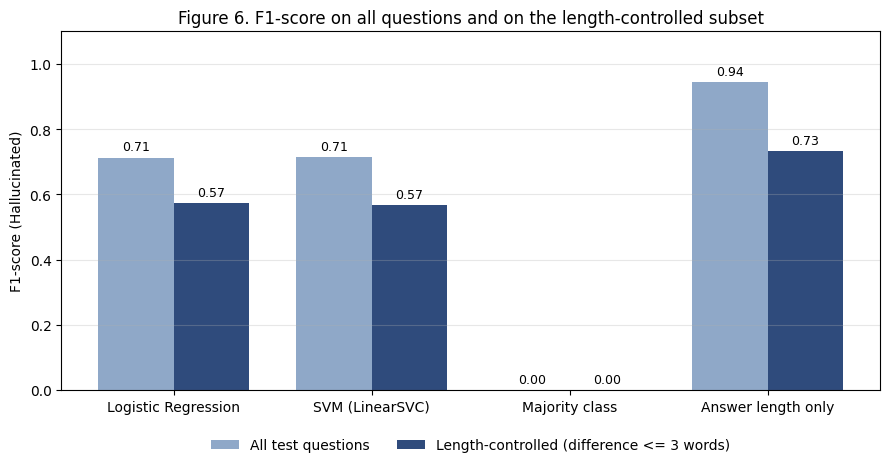

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.8))

names = list(controlled_table.index)
x = np.arange(len(names))
w = 0.38

full = controlled_table["F1 (all questions)"].to_numpy()
controlled = controlled_table["F1-score"].to_numpy()

b1 = ax.bar(x - w / 2, full, w, label="All test questions", color="#8FA8C8")
b2 = ax.bar(x + w / 2, controlled, w, label=f"Length-controlled (difference <= {LENGTH_DIFF_MAX} words)", color="#2F4B7C")
ax.bar_label(b1, labels=[f"{v:.2f}" for v in full], padding=3, fontsize=9)
ax.bar_label(b2, labels=[f"{v:.2f}" for v in controlled], padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1-score (Hallucinated)")
ax.set_title("Figure 6. F1-score on all questions and on the length-controlled subset")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "length_controlled_f1.png"), dpi=200, bbox_inches="tight")
plt.show()

## 9. Error Analysis

This section examines where and why the models fail: the agreement between the two compared models, the behaviour at the question level, and the effect of answer length and question type.

### 9.1 Agreement between the models

In [25]:
agreement = pd.Series({
    "Both correct": int((analysis[f"correct_{ka}"] & analysis[f"correct_{kb}"]).sum()),
    "Both wrong": int((~analysis[f"correct_{ka}"] & ~analysis[f"correct_{kb}"]).sum()),
    f"Only {MODEL_A} correct": only_a_correct,
    f"Only {MODEL_B} correct": only_b_correct,
}, name="Instances")

agreement_table = agreement.to_frame()
agreement_table["Share of test set"] = agreement_table["Instances"] / len(analysis)

print("Table 9. Agreement between the two compared models")
display(agreement_table.round(4))

Table 9. Agreement between the two compared models


,Instances,Share of test set
Both correct,2881,0.7202
Both wrong,1039,0.2598
Only Logistic Regression correct,36,0.0090
Only SVM (LinearSVC) correct,44,0.0110


### 9.2 Question-level analysis

Each test question has one faithful and one hallucinated answer, which allows two additional checks:

- **Outcome per question:** whether both answers are classified correctly, both are flagged as hallucinated, both are accepted as faithful, or the two labels are swapped.
- **Pairwise ranking accuracy:** the proportion of questions in which the hallucinated answer receives a higher score than the faithful answer. It measures whether the model orders the two answers correctly even when the decision threshold fails.

The pairwise comparison uses the other answer of the same question, which is not available in a real deployment. It is therefore used only as a diagnostic.

In [26]:
pair_rows = []
rank_rows = []

for name in models:
    k = KEY[name]
    piv = analysis.pivot(index="question", columns="label", values=[f"pred_{k}", f"score_{k}"])

    pred_h, pred_f = piv[(f"pred_{k}", 1)], piv[(f"pred_{k}", 0)]
    score_h, score_f = piv[(f"score_{k}", 1)], piv[(f"score_{k}", 0)]

    n_q = len(piv)
    pair_rows.append({
        "Model": name,
        "Both right": ((pred_h == 1) & (pred_f == 0)).sum() / n_q,
        "Both flagged hallucinated": ((pred_h == 1) & (pred_f == 1)).sum() / n_q,
        "Both accepted as faithful": ((pred_h == 0) & (pred_f == 0)).sum() / n_q,
        "Swapped": ((pred_h == 0) & (pred_f == 1)).sum() / n_q,
    })
    rank_rows.append({
        "Model": name,
        "Pairwise ranking accuracy": (score_h > score_f).mean(),
    })

pair_table = pd.DataFrame(pair_rows).set_index("Model")
rank_table = pd.DataFrame(rank_rows).set_index("Model")

print("Table 10. Outcome per question (share of the 2,000 test questions)")
display(pair_table.round(4))

print("\nTable 11. Pairwise ranking accuracy")
display(rank_table.round(4))

Table 10. Outcome per question (share of the 2,000 test questions)


,Both right,Both flagged hallucinated,Both accepted as faithful,Swapped
Model,,,,
Logistic Regression,0.4740,0.199,0.3115,0.0155
SVM (LinearSVC),0.4775,0.196,0.3115,0.0150



Table 11. Pairwise ranking accuracy


,Pairwise ranking accuracy
Model,
Logistic Regression,0.9155
SVM (LinearSVC),0.9185


### 9.3 Effect of answer length

The word counts of the answers are compared across the two classes. The error rate and the share of answers flagged as hallucinated are then reported for five answer-length groups (quintiles).

In [27]:
print("Average length in words, by true label:")
display(analysis.groupby("label")[["answer_words", "knowledge_words"]].agg(["mean", "median"]).round(1))

longer = (len_piv[1] > len_piv[0]).mean()
equal = (len_piv[1] == len_piv[0]).mean()
shorter = (len_piv[1] < len_piv[0]).mean()
print(f"\nPer question, the hallucinated answer is longer than the faithful one in {longer:.1%} of questions "
      f"(equal length: {equal:.1%}, shorter: {shorter:.1%}).")

analysis["answer_len_bin"] = pd.qcut(analysis["answer_words"], 5, duplicates="drop")

def length_summary(g):
    row = {"Instances": len(g), "True hallucinated (%)": 100 * g["label"].mean()}
    for name in models:
        k = KEY[name]
        row[f"{name} error rate (%)"] = 100 * (1 - g[f"correct_{k}"].mean())
        row[f"{name} flagged hallucinated (%)"] = 100 * g[f"pred_{k}"].mean()
    return pd.Series(row)

length_table = analysis.groupby("answer_len_bin", observed=True).apply(length_summary, include_groups=False)
length_table.index = length_table.index.astype(str)
length_table.index.name = "Answer length (words)"

print("\nTable 12. Errors by answer length (quintiles)")
display(length_table.round(1))

Average length in words, by true label:


answer_words        knowledge_words       
              mean median            mean median
label                                           
0              2.3    2.0            55.0   51.0
1             10.9    9.0            55.0   51.0


Per question, the hallucinated answer is longer than the faithful one in 96.5% of questions (equal length: 2.4%, shorter: 1.1%).

Table 12. Errors by answer length (quintiles)


,Instances,True hallucinated (%),Logistic Regression error rate (%),Logistic Regression flagged hallucinated (%),SVM (LinearSVC) error rate (%),SVM (LinearSVC) flagged hallucinated (%)
Answer length (words),,,,,,
"(0.999, 2.0]",1435.0,3.3,21.3,20.1,20.7,19.4
"(2.0, 3.0]",411.0,5.8,23.8,24.8,23.8,24.8
"(3.0, 6.0]",659.0,70.0,40.5,47.3,41.0,47.5
"(6.0, 11.0]",735.0,98.1,31.7,68.0,31.3,68.4
"(11.0, 81.0]",760.0,98.2,23.6,75.4,23.7,75.3


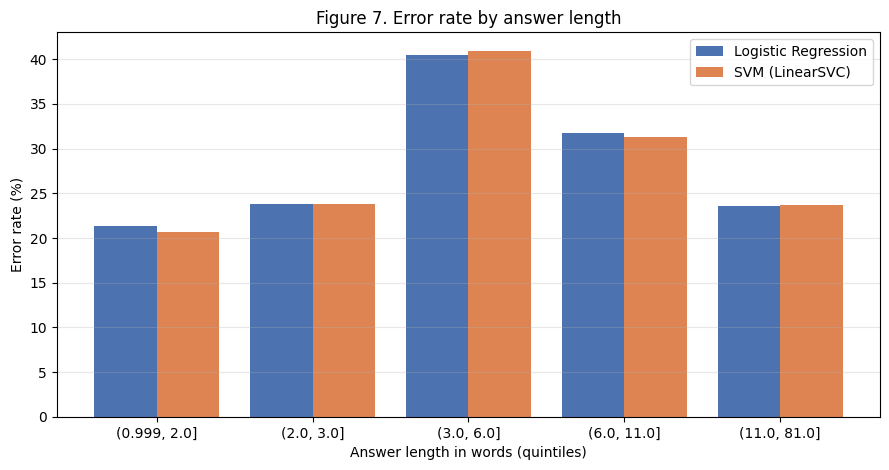

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.8))

bins = length_table.index
x = np.arange(len(bins))
w = 0.8 / len(models)

for i, name in enumerate(models):
    offset = (i - (len(models) - 1) / 2) * w
    ax.bar(x + offset, length_table[f"{name} error rate (%)"], w, label=name, color=COLORS[name])

ax.set_xticks(x)
ax.set_xticklabels(bins)
ax.set_xlabel("Answer length in words (quintiles)")
ax.set_ylabel("Error rate (%)")
ax.set_title("Figure 7. Error rate by answer length")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "error_rate_by_answer_length.png"), dpi=200, bbox_inches="tight")
plt.show()

### 9.4 Effect of question type

Questions are grouped by their first word (who, what, which, etc.). Questions that start with other words, such as yes/no questions, are grouped together.

In [29]:
def question_type(q):
    words = q.strip().lower().split()
    first = words[0] if words else ""
    for t in ["who", "what", "when", "where", "which", "how", "why"]:
        if first.startswith(t):
            return t
    return "other (yes/no, etc.)"

analysis["question_type"] = analysis["question"].apply(question_type)

def type_summary(g):
    row = {"Instances": len(g)}
    for name in models:
        row[f"{name} error rate (%)"] = 100 * (1 - g[f"correct_{KEY[name]}"].mean())
    return pd.Series(row)

qtype_table = analysis.groupby("question_type").apply(type_summary, include_groups=False)
qtype_table = qtype_table.sort_values("Instances", ascending=False)
qtype_table["Instances"] = qtype_table["Instances"].astype(int)

print("Table 13. Errors by question type")
display(qtype_table.round(1))

Table 13. Errors by question type


,Instances,Logistic Regression error rate (%),SVM (LinearSVC) error rate (%)
question_type,,,
"other (yes/no, etc.)",1952,26.7,26.9
what,926,27.1,26.5
which,512,32.0,31.1
who,336,25.3,25.0
when,116,20.7,20.7
where,88,18.2,19.3
how,70,30.0,30.0


### 9.5 Examples of misclassified answers

Random false negatives and false positives of the model with the highest test F1 are displayed to give a qualitative view of the errors.

In [30]:
k = KEY[best_model_name]

false_negatives = analysis[(analysis["label"] == 1) & (analysis[f"pred_{k}"] == 0)]
false_positives = analysis[(analysis["label"] == 0) & (analysis[f"pred_{k}"] == 1)]

def show_examples(df, title, n=4):
    print("=" * 90)
    print(f"{title} ({best_model_name}) - showing {n} of {len(df)}")
    print("=" * 90)
    for _, r in df.sample(n, random_state=RANDOM_STATE).iterrows():
        print(f"Question : {r['question'][:200]}")
        print(f"Answer   : {r['answer'][:200]}")
        print(f"Knowledge: {r['knowledge'][:250]}...")
        print(f"Model score: {r[f'score_{k}']:.3f}")
        print("-" * 90)

show_examples(false_negatives, "FALSE NEGATIVES: hallucinated answers accepted as faithful")
show_examples(false_positives, "FALSE POSITIVES: faithful answers flagged as hallucinated")

FALSE NEGATIVES: hallucinated answers accepted as faithful (SVM (LinearSVC)) - showing 4 of 653
Question : Tjeerd Eize Korf, a Dutch professional footballer from Flevoland, is the twelfth province of what country?
Answer   : Tjeerd Eize Korf, a Dutch professional footballer from Flevoland, is part of Germany.
Knowledge: Tjeerd Eize Korf (born 11 May 1983 in Emmeloord, Flevoland) is a Dutch professional footballer who currently plays as a striker for BV Veendam.Flevoland (] ) is the twelfth province of the Netherlands....
Model score: -0.024
------------------------------------------------------------------------------------------
Question : Which role did the only non-American from Pajama Party originate in the Broadway musical "Rent"?
Answer   : Daphne Rubin-Vega originated the role of Lucy.
Knowledge: Pajama Party was an American female vocal trio from Brooklyn, New York active between 1988 and 1992. The members were Jennifer McQuilkin of New Jersey, Daphne Rubin-Vega of Panama, and 

A simple lexical check follows: the share of answer words that also appear in the knowledge text. It indicates whether faithful and hallucinated answers differ in how much they overlap with the source, which TF-IDF over the concatenated text does not model explicitly.

In [31]:
def overlap_ratio(row):
    ans = set(row["answer"].lower().split())
    kn = set(row["knowledge"].lower().split())
    return len(ans & kn) / len(ans) if ans else 0.0

analysis["answer_in_knowledge"] = analysis.apply(overlap_ratio, axis=1)

print("Share of answer words that also appear in the knowledge, by true label:")
display(analysis.groupby("label")["answer_in_knowledge"].agg(["mean", "median"]).round(3))

print("\nSame measure for correct and wrong predictions of the best model:")
display(analysis.groupby(f"correct_{k}")["answer_in_knowledge"].agg(["mean", "median", "count"]).round(3))

Share of answer words that also appear in the knowledge, by true label:


,mean,median
label,,
0,0.690,1.000
1,0.533,0.559



Same measure for correct and wrong predictions of the best model:


,mean,median,count
correct_svm,,,
False,0.597,0.625,1075
True,0.617,0.667,2925


## 10. Best-Model Selection

Among the two trained models, the best one is selected using the F1-score of the Hallucinated class, which is the selection metric used during tuning. The result is checked against the statistical tests of Section 7 to determine whether the difference between the models is meaningful. The selected model is then compared with the answer-length baseline, to determine whether it adds anything beyond the shortcut.

In [32]:
winner_rows = []
for m in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    row = {"Metric": m}
    for name in models:
        row[name] = results.loc[name, m]
    row["Winner"] = results[m].idxmax()
    winner_rows.append(row)
winner_table = pd.DataFrame(winner_rows).set_index("Metric")

print("Table 14. Winner by metric among the trained models")
display(winner_table.round(4))

pair_diff = diff_table[(diff_table["Comparison"] == f"{MODEL_B} - {MODEL_A}") & (diff_table["Metric"] == "F1-score")].iloc[0]
print(f"Highest test F1: {best_model_name} = {results.loc[best_model_name, 'F1-score']:.4f}")
print(f"F1 difference ({MODEL_B} - {MODEL_A}): {pair_diff['Difference (test)']:.4f}")
print(f"95% bootstrap CI of the difference: [{pair_diff['95% CI low']:.4f}, {pair_diff['95% CI high']:.4f}]")
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")

if mcnemar_p < 0.05:
    print("The difference between the models is statistically significant.")
else:
    print("The difference between the models is not statistically significant: they are statistically tied.")

baseline_f1 = all_results.loc["Answer length only", "F1-score"]
best_f1 = results.loc[best_model_name, "F1-score"]
print(f"\nAnswer-length baseline F1: {baseline_f1:.4f}")
print(f"{best_model_name} F1: {best_f1:.4f}")

if best_f1 > baseline_f1:
    print("The selected model outperforms the answer-length baseline.")
else:
    print("The selected model does NOT outperform the answer-length baseline.")

Table 14. Winner by metric among the trained models


,Logistic Regression,SVM (LinearSVC),Winner
Metric,,,
Accuracy,0.7292,0.7312,SVM (LinearSVC)
Precision,0.7583,0.7614,SVM (LinearSVC)
Recall,0.6730,0.6735,SVM (LinearSVC)
F1-score,0.7131,0.7148,SVM (LinearSVC)
ROC-AUC,0.8067,0.8076,SVM (LinearSVC)


Highest test F1: SVM (LinearSVC) = 0.7148
F1 difference (SVM (LinearSVC) - Logistic Regression): 0.0017
95% bootstrap CI of the difference: [-0.0032, 0.0064]
McNemar exact test p-value: 0.4340
The difference between the models is not statistically significant: they are statistically tied.

Answer-length baseline F1: 0.9436
SVM (LinearSVC) F1: 0.7148
The selected model does NOT outperform the answer-length baseline.


## 11. Saving the Results

All tables, figures and the row-level predictions are saved in the `results` folder and downloaded as a single zip file for the project report and the repository.

In [33]:
results.round(4).to_csv(os.path.join(TABLES_DIR, "model_comparison.csv"))
generalisation.round(4).to_csv(os.path.join(TABLES_DIR, "train_validation_test_performance.csv"))
all_results.round(4).to_csv(os.path.join(TABLES_DIR, "models_vs_baselines.csv"))
cm_table.round(4).to_csv(os.path.join(TABLES_DIR, "confusion_matrix_summary.csv"))
ci_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_confidence_intervals.csv"), index=False)
diff_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_differences.csv"), index=False)
controlled_table.round(4).to_csv(os.path.join(TABLES_DIR, "length_controlled_results.csv"))
sensitivity_table.round(4).to_csv(os.path.join(TABLES_DIR, "length_threshold_sensitivity.csv"))
agreement_table.round(4).to_csv(os.path.join(TABLES_DIR, "model_agreement.csv"))
pair_table.round(4).to_csv(os.path.join(TABLES_DIR, "question_level_outcomes.csv"))
length_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_answer_length.csv"))
qtype_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_question_type.csv"))

prediction_columns = ["question", "answer", "label"] + [
    f"{prefix}_{KEY[name]}" for name in models for prefix in ("pred", "score")
]
analysis[prediction_columns].to_csv(os.path.join(TABLES_DIR, "test_predictions.csv"), index=False)

print("Saved tables:", sorted(os.listdir(TABLES_DIR)))
print("Saved figures:", sorted(os.listdir(FIGURES_DIR)))

shutil.make_archive("results", "zip", RESULTS_DIR)
files.download("results.zip")

Saved tables: ['bootstrap_confidence_intervals.csv', 'bootstrap_differences.csv', 'confusion_matrix_summary.csv', 'errors_by_answer_length.csv', 'errors_by_question_type.csv', 'length_controlled_results.csv', 'length_threshold_sensitivity.csv', 'model_agreement.csv', 'model_comparison.csv', 'models_vs_baselines.csv', 'question_level_outcomes.csv', 'test_predictions.csv', 'train_validation_test_performance.csv']
Saved figures: ['confusion_matrices_counts.png', 'confusion_matrices_normalized.png', 'error_rate_by_answer_length.png', 'length_controlled_f1.png', 'metrics_comparison.png', 'models_vs_baselines.png', 'roc_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusion

### Final results

| System | Accuracy | Precision | Recall | F1-score | F1 on the length-controlled subset (difference <= 3 words) |
|---|---|---|---|---|---|
| Logistic Regression | 0.7292 | 0.7583 | 0.6730 | 0.7131 | 0.5738 |
| **SVM (LinearSVC)** | **0.7312** | **0.7614** | **0.6735** | **0.7148** | **0.5676** |
| Majority class (baseline) | 0.5000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| Answer length only (baseline) | 0.9438 | 0.9458 | 0.9415 | 0.9436 | 0.7338 |

### Selected model: SVM (LinearSVC)
Between the two trained models, the SVM has the highest value on every metric and makes the fewest errors (1,075 versus 1,083). However, the gap is very small (F1 difference = 0.0017). The 95% bootstrap interval of the difference contains 0 for all four metrics, and McNemar's test gives p = 0.434. **The two models are therefore statistically tied on this test set.** We select the SVM because it is nominally best on every metric and is the model chosen by the project's selection rule (highest F1 on the Hallucinated class). Logistic Regression is an equally defensible choice if probability outputs are needed.

**This selection ranks the two models against each other only.** Neither of them outperforms the answer-length baseline, whose F1-score is about 0.23 higher than that of either model (95% bootstrap interval of the difference for the SVM: -0.244 to -0.214). The results therefore do not show that either model detects hallucinations well.

### Main findings
1. **Moderate performance and overfitting.** Both models reach about 73% test accuracy and about 0.71 F1. Test F1 is within about 0.005 of the cross-validation F1 reported by Students 1 and 2, so the validation estimate was reliable. However, the training F1 is about 0.87 and the training accuracy about 0.88, which is roughly 0.16 F1 and 14 accuracy points above the test scores. This indicates overfitting (high variance): with up to 20,000 unigram and bigram features, the models partly memorise the training data.
2. **A trivial baseline outperforms both models.** A classifier that sees only the length of the answer reaches an F1-score of 0.944 (95% interval 0.936 to 0.951), while the majority-class baseline reaches an accuracy of 0.50. In the HaluEval QA data, faithful answers average 2.3 words and hallucinated answers 10.9 words, and in 96.5% of the questions the hallucinated answer is the longer one. High scores on this dataset can therefore be obtained without comparing the answer with the knowledge, and the F1-score alone does not show that a model understands hallucination. The TF-IDF models exploit the length only partly: the share of answers they flag as hallucinated rises from about 20% for the shortest answers to about 75% for the longest, but they remain far below the baseline. A plausible reason is that TF-IDF normalises each text and the long knowledge passage dominates the short answer, but this explanation was not tested.
3. **Performance drops when answer length is controlled.** On the 332 questions whose two answers differ in length by at most three words, the F1-score falls to 0.57 for both models (95% intervals of about 0.53 to 0.61) and the accuracy to about 0.61 to 0.62, so a substantial part of their performance depends on length. The sensitivity analysis (Table 8) shows that the models stay between 0.52 and 0.63 F1 for thresholds from one to five words. The length baseline falls with the threshold: it equals the models at two words (0.57) and drops to 0.39 at one word (102 questions), whereas at three and five words it remains higher than the models (0.73 and 0.88), because answers of one to three words and of three to six words can still be separated by length. The performance of the models beyond answer length is therefore modest. The smaller subsets have wide confidence intervals, so these figures should be read as approximate.
4. **More missed hallucinations than false alarms.** Precision (about 0.76) is higher than recall (about 0.67). Each model misses about one third of the hallucinated answers (about 653 false negatives) and wrongly flags about 21% of the faithful answers (about 422 false positives). Since the project focuses on detecting hallucinated answers, the recall of the Hallucinated class is the main weakness.
5. **The two models behave almost identically.** They agree in correctness on 98% of the test set (72.0% both correct, 26.0% both wrong). This is expected, because both are linear models on the same TF-IDF features.
6. **The models rank answers better than they classify them.** Within a question, the hallucinated answer receives the higher score in about 92% of cases, while instance-level accuracy is only about 73%. For 31% of the questions both answers were accepted as faithful and for about 20% both were flagged as hallucinated. A single global threshold is therefore unreliable. This comparison uses the other answer of the same question, which is not available in the real task, so it is a diagnostic and not an achievable result.
7. **Question type.** Error rates range from about 18% to 32%. "Which" questions are the hardest among the larger groups (about 31%); "when" and "where" are easiest, but they have few test instances.

### Limitations and suggested next steps
- TF-IDF on the concatenated text does not explicitly compare the answer with the knowledge, so the models cannot truly check whether an answer is *supported*. Separate representations for the answer, the question and the knowledge, features that measure answer-knowledge overlap, or a model that reads the knowledge and the answer together (for example a fine-tuned transformer or an NLI model) would address the main weakness found here.
- The overfitting suggests using fewer features or stronger regularisation. Any new model should be compared with the answer-length baseline and evaluated on the length-controlled subset, and any new feature related to length should be reported as such.
- The baselines and the length-controlled evaluation were added after the first evaluation, following the instructor's feedback. The length threshold (three words) was fixed before the results were inspected, and the sensitivity to other thresholds is reported in Table 8. The test set was not used for tuning any model.
- The length-controlled subsets are small (102 to 733 questions), so differences of a few points between systems on them should not be treated as meaningful.
